# 06 — Building a Tiny Language Model with PyTorch

> **Goal:** Build, train, evaluate, and sample from a small autoregressive Transformer language model.

In the previous notebooks, we studied token IDs, Transformer components, and the next-token prediction objective. Now we connect those ideas in a real trainable model.

We will build a **small character-level causal Transformer** in PyTorch. Character-level tokenization keeps this first implementation easy to inspect. It is a teaching simplification: practical SLMs normally use subword or byte-level tokenizers, like the one explored in Notebook 02.

**What we will implement:** embeddings → positional information → causal self-attention → feed-forward network → logits → cross-entropy → gradient updates → autoregressive generation.

This is a miniature learning model, not a production-ready SLM.


## 1. What we are building

At each position, the model receives the characters before and including that position and predicts the next character.

The model will contain:

1. **Token embeddings:** turn character IDs into learned vectors.
2. **Position embeddings:** give the model information about sequence order.
3. **Causal Transformer blocks:** allow each position to attend only to itself and earlier positions.
4. **Feed-forward layers:** process each position's representation.
5. **Language-model head:** project hidden vectors into vocabulary-sized logits.

We will use a small pre-LayerNorm Transformer block with residual connections. Notebook 01 explained the components conceptually; here we make them trainable.


## 2. Imports and device selection

PyTorch provides tensors, automatic differentiation, neural-network layers, and optimizers.

The notebook automatically selects CUDA when available, otherwise it uses the CPU. The model is intentionally small so that it can run on ordinary hardware.


In [1]:
import math
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)
np.random.seed(42)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("PyTorch version:", torch.__version__)
print("Selected device:", device)

PyTorch version: 2.10.0+cpu
Selected device: cpu


## 3. Create a tiny training corpus

For a first model, we will use a small, deliberately repetitive corpus of short sentences about language models and learning.

A small corpus is useful for seeing whether the model can learn patterns, but it is not enough to create a useful general-purpose assistant. The goal is to understand the training mechanics.


In [2]:
base_sentences = [
    "small models learn patterns from text.",
    "tokens become vectors before attention.",
    "attention helps a model use context.",
    "a language model predicts the next token.",
    "training adjusts weights to reduce loss.",
    "data quality matters when models learn.",
    "a transformer uses attention and layers.",
    "good predictions assign probability to the target.",
    "the model reads context and predicts what comes next.",
    "we train a tiny model with pytorch.",
    "causal attention cannot look at future tokens.",
    "embeddings represent tokens as vectors.",
]

# Repeat and shuffle sentence order to create a compact toy corpus.
sentences = base_sentences * 40
rng = np.random.default_rng(42)
rng.shuffle(sentences)
text = "\n".join(sentences) + "\n"

print("Characters in corpus:", len(text))
print("Number of sentences:", len(sentences))
print("\nCorpus sample:\n")
print(text[:450])

Characters in corpus: 20320
Number of sentences: 480

Corpus sample:

good predictions assign probability to the target.
training adjusts weights to reduce loss.
attention helps a model use context.
a language model predicts the next token.
we train a tiny model with pytorch.
a language model predicts the next token.
a transformer uses attention and layers.
good predictions assign probability to the target.
training adjusts weights to reduce loss.
good predictions assign probability to the target.
a transformer use


## 4. Build a character tokenizer

Our vocabulary contains each unique character in the corpus.

- `stoi` maps a character to an integer ID.
- `itos` maps an integer ID back to a character.
- `encode` converts text to IDs.
- `decode` converts IDs back to text.

This tokenizer is intentionally simple. It has no unknown-token handling because we will generate only from the vocabulary built from this corpus.


In [3]:
chars = sorted(set(text))
vocab_size = len(chars)

stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

def encode(s):
    return [stoi[ch] for ch in s]

def decode(ids):
    return "".join(itos[int(i)] for i in ids)

all_ids = torch.tensor(encode(text), dtype=torch.long)

print("Vocabulary size:", vocab_size)
print("Vocabulary:", repr("".join(chars)))
print("Text sample:", repr(text[:80]))
print("Encoded sample:", all_ids[:30].tolist())
print("Decoded sample:", repr(decode(all_ids[:30].tolist())))

Vocabulary size: 28
Vocabulary: '\n .abcdefghijklmnopqrstuvwxy'
Text sample: 'good predictions assign probability to the target.\ntraining adjusts weights to r'
Encoded sample: [9, 17, 17, 6, 1, 18, 20, 7, 6, 11, 5, 22, 11, 17, 16, 21, 1, 3, 21, 21, 11, 9, 16, 1, 18, 20, 17, 4, 3, 4]
Decoded sample: 'good predictions assign probab'


## 5. Train and validation split

We split the encoded corpus into two contiguous parts. Training windows are sampled only from the training portion. Validation windows are sampled only from the held-out portion.

This is a simple demonstration split. For serious language-model evaluation, data should be split at the document or source level where appropriate, and duplicate or near-duplicate leakage should be checked.


In [4]:
split_index = int(0.9 * len(all_ids))
train_data = all_ids[:split_index]
val_data = all_ids[split_index:]

print("Train characters:", len(train_data))
print("Validation characters:", len(val_data))

Train characters: 18288
Validation characters: 2032


## 6. Context length and next-character batches

`block_size` is the maximum context length used by this tiny model.

For each sampled window:
- `x` contains the characters the model sees.
- `y` contains the next-character targets.

The target is shifted one position to the left, just like the input/target construction in Notebook 04.

Each row is an independent training example. The model produces a prediction at every position in the row.


In [5]:
block_size = 48
batch_size = 32

def get_batch(split):
    source = train_data if split == "train" else val_data
    # Each start index must leave room for block_size + 1 tokens.
    starts = torch.randint(0, len(source) - block_size - 1, (batch_size,))
    x = torch.stack([source[i:i + block_size] for i in starts])
    y = torch.stack([source[i + 1:i + block_size + 1] for i in starts])
    return x.to(device), y.to(device)

xb, yb = get_batch("train")
print("Input batch shape:", tuple(xb.shape))
print("Target batch shape:", tuple(yb.shape))
print("\nInput example: ", repr(decode(xb[0].tolist())))
print("Target example:", repr(decode(yb[0].tolist())))

Input batch shape: (32, 48)
Target batch shape: (32, 48)

Input example:  'ectors before attention.\nthe model reads context'
Target example: 'ctors before attention.\nthe model reads context '


## 7. Inspect the prediction alignment

At every time step, the model predicts the next character. For example, if an input row begins with `s m a l l`, its target row begins with `m a l l ...`.

The model's output at position `t` is compared with target position `t`. The causal mask ensures that the prediction at position `t` cannot use later input positions.


In [6]:
for t in range(12):
    print(f"input[{t}] = {decode([xb[0, t].item()])!r}  ->  target[{t}] = {decode([yb[0, t].item()])!r}")

input[0] = 'e'  ->  target[0] = 'c'
input[1] = 'c'  ->  target[1] = 't'
input[2] = 't'  ->  target[2] = 'o'
input[3] = 'o'  ->  target[3] = 'r'
input[4] = 'r'  ->  target[4] = 's'
input[5] = 's'  ->  target[5] = ' '
input[6] = ' '  ->  target[6] = 'b'
input[7] = 'b'  ->  target[7] = 'e'
input[8] = 'e'  ->  target[8] = 'f'
input[9] = 'f'  ->  target[9] = 'o'
input[10] = 'o'  ->  target[10] = 'r'
input[11] = 'r'  ->  target[11] = 'e'


## 8. Model configuration

We will keep the model small:

- Embedding dimension: 64
- Attention heads: 4
- Transformer blocks: 2
- Context length: 48
- Dropout: 0.1

The embedding dimension must be divisible by the number of attention heads. Each head receives an equal slice of the embedding dimension.


In [7]:
batch_size = 32
block_size = 48
n_embd = 64
n_head = 4
n_layer = 2
dropout = 0.1

assert n_embd % n_head == 0
print("Head dimension:", n_embd // n_head)

Head dimension: 16


## 9. Causal self-attention

For each token representation, attention creates queries, keys, and values.

The attention score matrix is:

\[
S = \frac{QK^T}{\sqrt{d_k}}
\]

We apply a lower-triangular causal mask before softmax. This sets future-token scores to negative infinity, so their attention probabilities become zero.

Then:

\[
\operatorname{Attention}(Q,K,V)=\operatorname{softmax}(S)V
\]

We implement multi-head attention by splitting the embedding dimension into multiple heads, performing attention independently, then joining the heads.


In [8]:
class CausalSelfAttention(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        assert n_embd % n_head == 0
        self.n_head = n_head
        self.head_dim = n_embd // n_head

        self.qkv = nn.Linear(n_embd, 3 * n_embd, bias=False)
        self.proj = nn.Linear(n_embd, n_embd)
        self.attn_dropout = nn.Dropout(dropout)
        self.resid_dropout = nn.Dropout(dropout)

        # True values are positions a token is allowed to attend to.
        causal_mask = torch.tril(torch.ones(block_size, block_size, dtype=torch.bool))
        self.register_buffer("causal_mask", causal_mask)

    def forward(self, x):
        B, T, C = x.shape
        q, k, v = self.qkv(x).chunk(3, dim=-1)

        # (B, T, C) -> (B, heads, T, head_dim)
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        scores = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        mask = self.causal_mask[:T, :T]
        scores = scores.masked_fill(~mask, float("-inf"))

        weights = F.softmax(scores, dim=-1)
        weights = self.attn_dropout(weights)
        output = weights @ v

        output = output.transpose(1, 2).contiguous().view(B, T, C)
        output = self.resid_dropout(self.proj(output))
        return output

## 10. Feed-forward network and Transformer block

The feed-forward network applies the same small MLP independently at every sequence position.

Our Transformer block uses:
- Layer normalization before each sub-layer (pre-LN).
- A residual connection around attention.
- A residual connection around the feed-forward network.

Residual connections help information and gradients flow through the network.


In [9]:
class FeedForward(nn.Module):
    def __init__(self, n_embd, dropout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd),
            nn.GELU(),
            nn.Linear(4 * n_embd, n_embd),
            nn.Dropout(dropout),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, n_embd, n_head, block_size, dropout):
        super().__init__()
        self.ln1 = nn.LayerNorm(n_embd)
        self.attn = CausalSelfAttention(n_embd, n_head, block_size, dropout)
        self.ln2 = nn.LayerNorm(n_embd)
        self.ffwd = FeedForward(n_embd, dropout)

    def forward(self, x):
        x = x + self.attn(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x

## 11. The complete language model

The model combines token embeddings, positional embeddings, Transformer blocks, final normalization, and an output projection.

The output has shape:

\[
(B, T, V)
\]

where:
- \(B\) = batch size,
- \(T\) = sequence length,
- \(V\) = vocabulary size.

Each position receives one logit for every possible next character.


In [10]:
class TinyLanguageModel(nn.Module):
    def __init__(self, vocab_size, n_embd, n_head, n_layer, block_size, dropout):
        super().__init__()
        self.block_size = block_size
        self.token_embedding = nn.Embedding(vocab_size, n_embd)
        self.position_embedding = nn.Embedding(block_size, n_embd)

        self.blocks = nn.Sequential(*[
            TransformerBlock(n_embd, n_head, block_size, dropout)
            for _ in range(n_layer)
        ])

        self.final_norm = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        if T > self.block_size:
            raise ValueError("Input sequence is longer than the configured block size.")

        positions = torch.arange(T, device=idx.device)
        x = self.token_embedding(idx) + self.position_embedding(positions)
        x = self.blocks(x)
        x = self.final_norm(x)
        logits = self.lm_head(x)

        loss = None
        if targets is not None:
            B, T, V = logits.shape
            loss = F.cross_entropy(
                logits.reshape(B * T, V),
                targets.reshape(B * T)
            )

        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        self.eval()
        for _ in range(max_new_tokens):
            # Keep only the most recent context that fits the model.
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)

            # Use only the final position's prediction.
            logits = logits[:, -1, :] / max(temperature, 1e-5)

            if top_k is not None:
                k = min(top_k, logits.size(-1))
                values, _ = torch.topk(logits, k)
                cutoff = values[:, [-1]]
                logits = logits.masked_fill(logits < cutoff, float("-inf"))

            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, num_samples=1)
            idx = torch.cat((idx, next_id), dim=1)

        return idx

## 12. Instantiate the model and inspect its size

We count trainable parameters to get a sense of the model's scale. This is a deliberately tiny network, much smaller than modern SLMs.


In [11]:
model = TinyLanguageModel(
    vocab_size=vocab_size,
    n_embd=n_embd,
    n_head=n_head,
    n_layer=n_layer,
    block_size=block_size,
    dropout=dropout,
).to(device)

parameter_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\nTrainable parameters: {parameter_count:,}")

TinyLanguageModel(
  (token_embedding): Embedding(28, 64)
  (position_embedding): Embedding(48, 64)
  (blocks): Sequential(
    (0): TransformerBlock(
      (ln1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (attn): CausalSelfAttention(
        (qkv): Linear(in_features=64, out_features=192, bias=False)
        (proj): Linear(in_features=64, out_features=64, bias=True)
        (attn_dropout): Dropout(p=0.1, inplace=False)
        (resid_dropout): Dropout(p=0.1, inplace=False)
      )
      (ln2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (ffwd): FeedForward(
        (net): Sequential(
          (0): Linear(in_features=64, out_features=256, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=256, out_features=64, bias=True)
          (3): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (1): TransformerBlock(
      (ln1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (attn): CausalSelfAttention(
     

## 13. Run a forward pass before training

Before optimizing anything, check that the model accepts a batch and returns logits with the expected shape.

This is a useful debugging habit: verify tensor shapes before writing the training loop.


In [12]:
model.eval()
with torch.no_grad():
    sample_x, sample_y = get_batch("train")
    sample_logits, sample_loss = model(sample_x, sample_y)

print("Input shape: ", tuple(sample_x.shape))
print("Logits shape:", tuple(sample_logits.shape))
print("Initial loss:", float(sample_loss))

Input shape:  (32, 48)
Logits shape: (32, 48, 28)
Initial loss: 3.4716012477874756


The logits' last dimension equals the vocabulary size. The loss is a scalar because PyTorch's cross-entropy averages the token-level losses across the batch and sequence positions.

At initialization, the loss should be in the general neighborhood of \(\ln(V)\), though the exact value depends on the random initial parameters.


## 14. Estimate train and validation loss

We evaluate on several random batches and average the results. `model.eval()` disables dropout during evaluation; `torch.no_grad()` avoids storing gradients.

The validation loss is measured on held-out text, not on the batches used for gradient updates.


In [13]:
@torch.no_grad()
def estimate_loss(eval_batches=10):
    model.eval()
    results = {}
    for split in ["train", "val"]:
        losses = []
        for _ in range(eval_batches):
            x, y = get_batch(split)
            _, loss = model(x, y)
            losses.append(loss.item())
        results[split] = float(np.mean(losses))
    model.train()
    return results

print(estimate_loss())

{'train': 3.495789051055908, 'val': 3.478307914733887}


## 15. Train the model

The training loop repeats the following process:

1. Sample a batch of input and target sequences.
2. Run the model to calculate logits and cross-entropy.
3. Clear old gradients.
4. Backpropagate the loss.
5. Update parameters with AdamW.

We use a modest number of iterations so the notebook remains quick. Loss values will vary because batches are randomly sampled and the corpus is tiny.


In [14]:
learning_rate = 3e-4
max_iters = 250
eval_interval = 50

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)

train_history = []
val_history = []
step_history = []

start_time = time.time()
model.train()

for step in range(1, max_iters + 1):
    xb, yb = get_batch("train")

    logits, loss = model(xb, yb)

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    if step == 1 or step % eval_interval == 0 or step == max_iters:
        metrics = estimate_loss(eval_batches=8)
        step_history.append(step)
        train_history.append(metrics["train"])
        val_history.append(metrics["val"])
        print(
            f"step {step:3d}/{max_iters} | "
            f"train loss {metrics['train']:.4f} | "
            f"val loss {metrics['val']:.4f}"
        )

elapsed = time.time() - start_time
print(f"\nTraining time: {elapsed:.1f} seconds")

step   1/250 | train loss 3.4699 | val loss 3.4646


step  50/250 | train loss 2.6712 | val loss 2.6649


step 100/250 | train loss 2.3316 | val loss 2.3193


step 150/250 | train loss 2.1730 | val loss 2.1680


step 200/250 | train loss 2.0472 | val loss 2.0460


step 250/250 | train loss 1.9493 | val loss 1.9481

Training time: 9.3 seconds


## 16. Plot the learning curves

A falling training loss suggests the model is fitting patterns in its training data. Validation loss helps us see whether those patterns transfer to held-out text.

With a small repetitive corpus, these curves are only a learning demonstration. They are not evidence of broad language understanding.


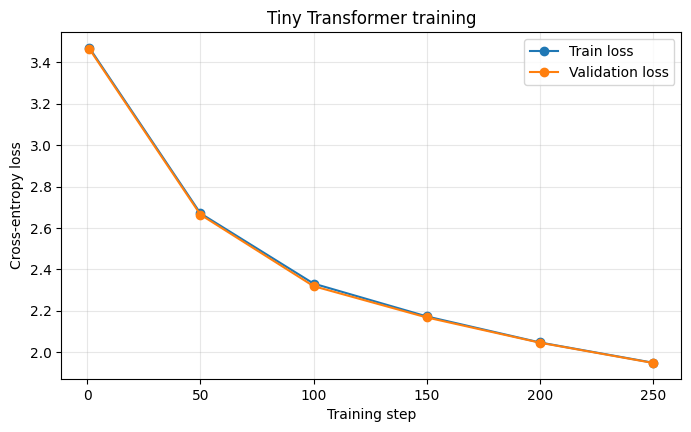

In [15]:
plt.figure(figsize=(8, 4.5))
plt.plot(step_history, train_history, marker="o", label="Train loss")
plt.plot(step_history, val_history, marker="o", label="Validation loss")
plt.xlabel("Training step")
plt.ylabel("Cross-entropy loss")
plt.title("Tiny Transformer training")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 17. Generate text autoregressively

Generation starts from a prompt. The model:
1. Reads the current context.
2. Computes logits at each position.
3. Uses the final position's logits to obtain next-character probabilities.
4. Samples one character.
5. Appends it to the context.
6. Repeats.

Temperature controls the sharpness of the probability distribution:
- Lower temperature makes the distribution more concentrated.
- Higher temperature makes it flatter and more random.

Top-k sampling optionally restricts sampling to the k highest-scoring characters.


In [16]:
model.eval()

def generate_from_prompt(prompt, max_new_tokens=180, temperature=0.8, top_k=8):
    if not prompt:
        prompt = " "
    # This toy character tokenizer requires every prompt character to be in its vocabulary.
    unknown = [ch for ch in prompt if ch not in stoi]
    if unknown:
        raise ValueError(f"Prompt contains characters outside the training vocabulary: {unknown}")

    context = torch.tensor([encode(prompt)], dtype=torch.long, device=device)
    generated = model.generate(
        context,
        max_new_tokens=max_new_tokens,
        temperature=temperature,
        top_k=top_k,
    )
    return decode(generated[0].tolist())

print(generate_from_prompt("small models", max_new_tokens=180))

small models padecad chendels ats vexteles prs.
ts.
ctok prntttherns morele as a todediodela telattecto ts l an t ats atodua at.
ct.
t mors atornn mod adengel ction ton.
then conts te mes mext


### Try different prompts and sampling settings

The model is trained on a tiny corpus with a narrow vocabulary and repeated sentence patterns. Experiment with prompts that resemble the training examples.


In [17]:
for prompt in ["attention", "the model", "tokens", "training"]:
    print(f"\nPrompt: {prompt!r}")
    print(generate_from_prompt(prompt, max_new_tokens=100, temperature=0.7, top_k=6))


Prompt: 'attention'
attention t prs prodextelokhe mokent.
atok tel tens ttorel atoken.
s tiomons l men pre a l tenghentelent.
ato

Prompt: 'the model'


the modelel l weat.
treateden.
ted arsengerelel l l a prelen contens atoren lods pren prel prntt.
aten angedi

Prompt: 'tokens'
tokens.
ate tomen tr momoken mode mexte moneda t.
titel codins we pa prens lan tin a l prent tentonse arel

Prompt: 'training'


training t ton ton mhe thedus at.
tt prntodens a atodentoke te l lodigoken wentelextiore tedede ant.
tt.
s t


## 18. What this model does not include yet

This is a useful first end-to-end training example, but it is intentionally simplified.

- **Character tokenizer:** real SLMs generally use subword or byte-level tokenization.
- **Tiny corpus:** real pretraining requires much larger, carefully curated datasets.
- **Small context:** modern models often use much longer contexts.
- **Small architecture:** real SLMs use more layers, parameters, and training optimizations.
- **No distributed training:** we train on one device in one process.
- **No checkpointing or experiment tracking:** omitted to keep the learning code focused.
- **No instruction tuning:** this is next-token pretraining, not a chat assistant.

The central training mechanism, however, is the same: produce logits for next-token targets, calculate a loss, backpropagate gradients, and update parameters.


## 19. Exercises

1. Change `n_embd` from 64 to 96. What must you check about `n_head`?
2. Change `n_layer` from 2 to 3. How does the parameter count change?
3. Train for more iterations. Does validation loss keep decreasing?
4. Set `temperature=0.3`, then `temperature=1.2`. Compare the generated text.
5. Remove the causal mask temporarily (for experimentation only). Why would that make training invalid for autoregressive next-token prediction?
6. Why can this character-level model not be directly compared with a subword-tokenized model's perplexity?

### Small experiment: count parameters

Run this cell to see how embedding size and layer count affect a rough model-size estimate. Then compare with the actual count printed above.


In [18]:
def count_parameters(module):
    return sum(p.numel() for p in module.parameters() if p.requires_grad)

print("Actual trainable parameter count:", count_parameters(model))
print("Vocabulary size:", vocab_size)
print("Embedding dimension:", n_embd)
print("Transformer blocks:", n_layer)
print("Attention heads:", n_head)

Actual trainable parameter count: 106396
Vocabulary size: 28
Embedding dimension: 64
Transformer blocks: 2
Attention heads: 4


## 20. Notebook summary

You have now built and trained a tiny causal Transformer language model.

You implemented:
- A character tokenizer and integer token IDs.
- Shifted input/target batches.
- Learned token and positional embeddings.
- Multi-head causal self-attention.
- Feed-forward layers, residual connections, and LayerNorm.
- Vocabulary logits and cross-entropy loss.
- An AdamW training loop.
- Train/validation loss tracking.
- Autoregressive text generation.

**The most important connection:** the architecture produces logits, the language-model objective turns those logits into a loss, and backpropagation plus an optimizer updates the model so that correct next characters receive higher probability.

### Next notebook

**Notebook 07 — Training Improvements: Batches, Checkpoints, and Better Evaluation**

We will improve the training workflow without turning the repository into a complicated framework: reproducible runs, checkpoint saving/loading, more reliable evaluation, and understanding overfitting.
